In [2]:
import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay

np.random.seed(42)

# Load Iris dataset
iris = load_iris()

# Use two features so we can visualize decision boundaries in 2D
X = iris.data[:, 2:4]  # Petal length and petal width
y = iris.target

class_names = iris.target_names
n_samples, n_features = X.shape
n_classes = len(np.unique(y))

print("X shape:", X.shape)
print("y shape:", y.shape)
print("Number of features:", n_features)
print("Number of classes:", n_classes)
print("Classes:", class_names)

X shape: (150, 2)
y shape: (150,)
Number of features: 2
Number of classes: 3
Classes: ['setosa' 'versicolor' 'virginica']


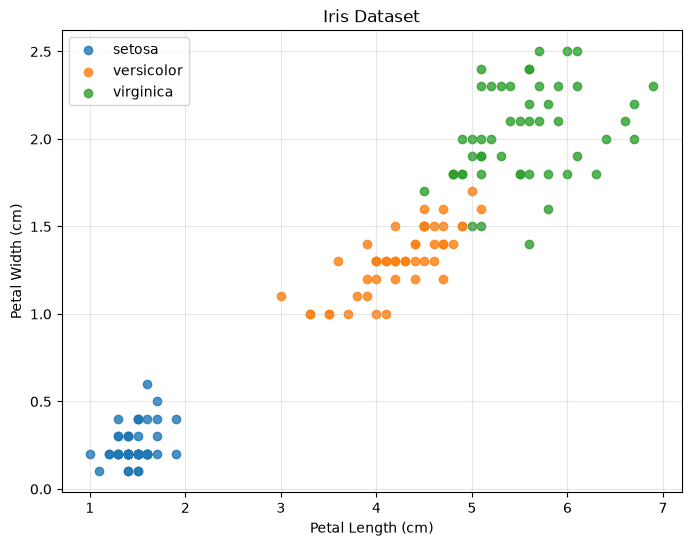

In [3]:
plt.figure(figsize=(8, 6))

for class_id, class_name in enumerate(class_names):
    plt.scatter(
        X[y == class_id, 0],
        X[y == class_id, 1],
        label=class_name,
        alpha=0.8
    )

plt.xlabel("Petal Length (cm)")
plt.ylabel("Petal Width (cm)")
plt.title("Iris Dataset")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (120, 2)
X_test: (30, 2)
y_train: (120,)
y_test: (30,)


In [5]:
mean = X_train.mean(axis=0)
std = X_train.std(axis=0)

X_train_scaled = (X_train - mean) / std
X_test_scaled = (X_test - mean) / std

print("Training feature means:", X_train_scaled.mean(axis=0))
print("Training feature stds:", X_train_scaled.std(axis=0))

Training feature means: [4.99600361e-16 1.67458640e-15]
Training feature stds: [1. 1.]


In [6]:
Y_train = np.eye(n_classes)[y_train]

print("Original labels:")
print(y_train[:5])

print("\nOne-hot labels:")
print(Y_train[:5])

print("\nOne-hot shape:", Y_train.shape)

Original labels:
[0 2 1 0 1]

One-hot labels:
[[1. 0. 0.]
 [0. 0. 1.]
 [0. 1. 0.]
 [1. 0. 0.]
 [0. 1. 0.]]

One-hot shape: (120, 3)


In [7]:
def softmax(Z):
    # Numerical stability: subtract the maximum logit in each row
    Z_shifted = Z - np.max(Z, axis=1, keepdims=True)

    exp_Z = np.exp(Z_shifted)

    probabilities = exp_Z / np.sum(
        exp_Z,
        axis=1,
        keepdims=True
    )

    return probabilities

In [8]:
def cross_entropy_loss(Y, probabilities):
    eps = 1e-15

    probabilities = np.clip(
        probabilities,
        eps,
        1 - eps
    )

    loss = -np.mean(
        np.sum(Y * np.log(probabilities), axis=1)
    )

    return loss

In [9]:
W = np.random.randn(n_features, n_classes) * 0.01
b = np.zeros(n_classes)

print("W shape:", W.shape)
print("b shape:", b.shape)

print("\nW:")
print(W)

print("\nb:")
print(b)

W shape: (2, 3)
b shape: (3,)

W:
[[ 0.00496714 -0.00138264  0.00647689]
 [ 0.0152303  -0.00234153 -0.00234137]]

b:
[0. 0. 0.]


In [10]:
def forward(X, W, b):
    Z = X @ W + b
    probabilities = softmax(Z)

    return Z, probabilities

In [11]:
Z, probabilities = forward(X_train_scaled, W, b)

print("Z shape:", Z.shape)
print("Probabilities shape:", probabilities.shape)

print("\nFirst three logits:")
print(Z[:3])

print("\nFirst three probability distributions:")
print(probabilities[:3])

print("\nSum of probabilities for each sample:")
print(probabilities[:3].sum(axis=1))

Z shape: (120, 3)
Probabilities shape: (120, 3)

First three logits:
[[-0.02683828  0.00495915 -0.00561781]
 [ 0.01198544 -0.00209924  0.00115869]
 [ 0.00681549 -0.00140984  0.00318685]]

First three probability distributions:
[[0.32746563 0.33804551 0.33448886]
 [0.3361067  0.33140592 0.33248738]
 [0.33465115 0.33190983 0.33343902]]

Sum of probabilities for each sample:
[1. 1. 1.]


In [12]:
learning_rate = 0.1
epochs = 2000

loss_history = []
accuracy_history = []

N = X_train_scaled.shape[0]

for epoch in range(epochs):

    # Forward propagation
    Z, probabilities = forward(
        X_train_scaled,
        W,
        b
    )

    # Calculate loss
    loss = cross_entropy_loss(
        Y_train,
        probabilities
    )

    # Calculate predictions and accuracy
    predictions = np.argmax(probabilities, axis=1)
    accuracy = np.mean(predictions == y_train)

    loss_history.append(loss)
    accuracy_history.append(accuracy)

    # Backpropagation
    dZ = probabilities - Y_train

    dW = (X_train_scaled.T @ dZ) / N
    db = np.mean(dZ, axis=0)

    # Gradient descent update
    W -= learning_rate * dW
    b -= learning_rate * db

    if epoch % 200 == 0:
        print(
            f"Epoch {epoch:4d} | "
            f"Loss: {loss:.4f} | "
            f"Accuracy: {accuracy:.4f}"
        )

Epoch    0 | Loss: 1.1061 | Accuracy: 0.0333
Epoch  200 | Loss: 0.2711 | Accuracy: 0.9667
Epoch  400 | Loss: 0.1931 | Accuracy: 0.9583
Epoch  600 | Loss: 0.1588 | Accuracy: 0.9583
Epoch  800 | Loss: 0.1393 | Accuracy: 0.9583
Epoch 1000 | Loss: 0.1267 | Accuracy: 0.9583
Epoch 1200 | Loss: 0.1177 | Accuracy: 0.9583
Epoch 1400 | Loss: 0.1111 | Accuracy: 0.9583
Epoch 1600 | Loss: 0.1059 | Accuracy: 0.9583
Epoch 1800 | Loss: 0.1017 | Accuracy: 0.9583


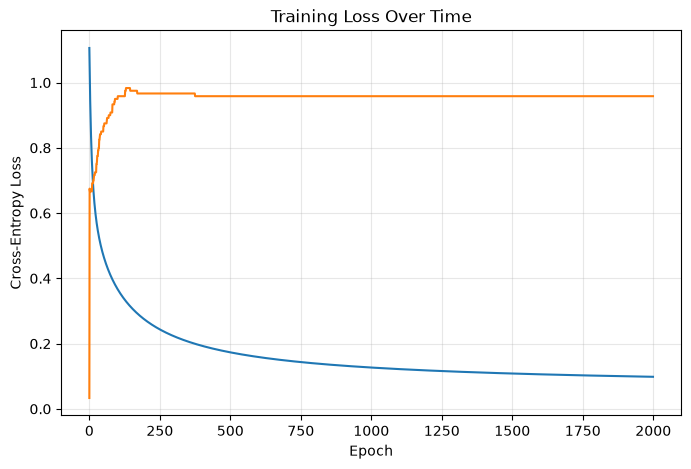

In [18]:
plt.figure(figsize=(8, 5))

plt.plot(loss_history)
plt.plot(accuracy_history)

plt.xlabel("Epoch")
plt.ylabel("Cross-Entropy Loss")
plt.title("Training Loss Over Time")
plt.grid(alpha=0.3)

plt.show()

In [14]:
Z_test, test_probabilities = forward(
    X_test_scaled,
    W,
    b
)

y_pred = np.argmax(test_probabilities, axis=1)

test_accuracy = accuracy_score(
    y_test,
    y_pred
)

print(f"Test accuracy: {test_accuracy:.4f}")

print("\nFirst 10 actual labels:")
print(y_test[:10])

print("\nFirst 10 predicted labels:")
print(y_pred[:10])

print("\nFirst 10 probability distributions:")
print(np.round(test_probabilities[:10], 3))

Test accuracy: 0.9333

First 10 actual labels:
[0 2 1 1 0 1 0 0 2 1]

First 10 predicted labels:
[0 2 1 1 0 1 0 0 2 1]

First 10 probability distributions:
[[0.994 0.006 0.   ]
 [0.    0.247 0.753]
 [0.121 0.878 0.001]
 [0.121 0.878 0.001]
 [0.994 0.006 0.   ]
 [0.001 0.628 0.372]
 [0.997 0.003 0.   ]
 [0.984 0.016 0.   ]
 [0.    0.051 0.949]
 [0.002 0.817 0.181]]


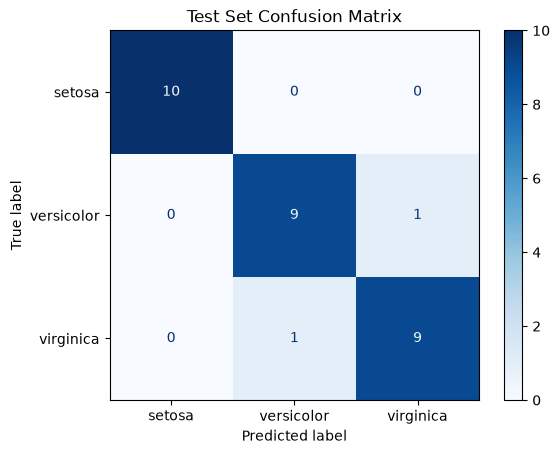

In [15]:
cm = confusion_matrix(
    y_test,
    y_pred,
    labels=np.arange(n_classes)
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)

disp.plot(cmap="Blues")

plt.title("Test Set Confusion Matrix")
plt.show()

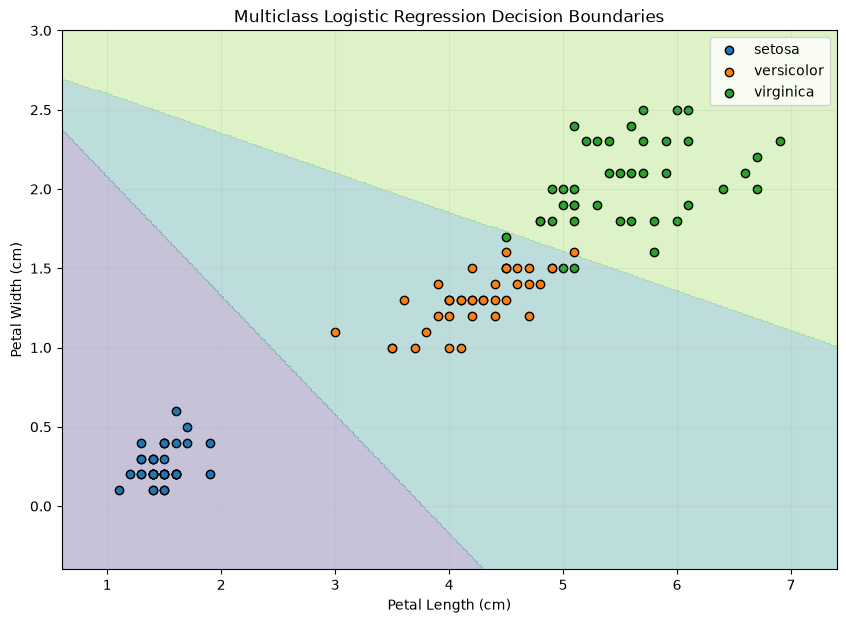

In [16]:
def plot_decision_boundaries(
    X,
    y,
    W,
    b,
    mean,
    std,
    class_names
):
    x_min, x_max = X[:, 0].min() - 0.5, X[:, 0].max() + 0.5
    y_min, y_max = X[:, 1].min() - 0.5, X[:, 1].max() + 0.5

    xx, yy = np.meshgrid(
        np.linspace(x_min, x_max, 300),
        np.linspace(y_min, y_max, 300)
    )

    grid = np.c_[xx.ravel(), yy.ravel()]

    # Apply the same scaling used during training
    grid_scaled = (grid - mean) / std

    # Predict the class at every grid point
    _, grid_probabilities = forward(
        grid_scaled,
        W,
        b
    )

    grid_predictions = np.argmax(
        grid_probabilities,
        axis=1
    )

    grid_predictions = grid_predictions.reshape(
        xx.shape
    )

    plt.figure(figsize=(10, 7))

    plt.contourf(
        xx,
        yy,
        grid_predictions,
        alpha=0.3,
        levels=np.arange(n_classes + 1) - 0.5
    )

    for class_id, class_name in enumerate(class_names):
        plt.scatter(
            X[y == class_id, 0],
            X[y == class_id, 1],
            label=class_name,
            edgecolors="black"
        )

    plt.xlabel("Petal Length (cm)")
    plt.ylabel("Petal Width (cm)")
    plt.title("Multiclass Logistic Regression Decision Boundaries")
    plt.legend()
    plt.grid(alpha=0.2)
    plt.show()


plot_decision_boundaries(
    X_train,
    y_train,
    W,
    b,
    mean,
    std,
    class_names
)

In [17]:
x = X_train_scaled[0:1]
y_one_hot = Y_train[0:1]

Z = x @ W + b
P = softmax(Z)

dZ = P - y_one_hot
dW = x.T @ dZ
db = dZ[0]

print("Input x:", x)
print("Input shape:", x.shape)

print("\nWeights W:")
print(W)
print("W shape:", W.shape)

print("\nLogits Z:")
print(Z)
print("Z shape:", Z.shape)

print("\nProbabilities P:")
print(P)
print("P shape:", P.shape)

print("\nTrue one-hot label:")
print(y_one_hot)

print("\nGradient dZ = P - Y:")
print(dZ)

print("\nGradient dW:")
print(dW)
print("dW shape:", dW.shape)

print("\nGradient db:")
print(db)
print("db shape:", db.shape)

Input x: [[-1.34572231 -1.32327558]]
Input shape: (1, 2)

Weights W:
[[-3.64408545  0.39181899  3.26232784]
 [-3.20547358 -0.88424954  4.10027052]]
W shape: (2, 3)

Logits Z:
[[  8.2323539    3.4157752  -11.67562604]]
Z shape: (1, 3)

Probabilities P:
[[9.91970558e-01 8.02943948e-03 2.24167655e-09]]
P shape: (1, 3)

True one-hot label:
[[1. 0. 0.]]

Gradient dZ = P - Y:
[[-8.02944172e-03  8.02943948e-03  2.24167655e-09]]

Gradient dW:
[[ 1.08053988e-02 -1.08053958e-02 -3.01667414e-09]
 [ 1.06251642e-02 -1.06251612e-02 -2.96635584e-09]]
dW shape: (2, 3)

Gradient db:
[-8.02944172e-03  8.02943948e-03  2.24167655e-09]
db shape: (3,)
